# Movies Project Starter

Use this starter notebook for the BAN 6003 final project option: **The Movies Dataset / MovieLens ratings**.

Run cells from top to bottom first. Then replace starter notes with your own project decisions, checks, and interpretation.

Start each milestone by reading the matching Canvas milestone assignment page. The Canvas page tells you exactly what evidence and submission items are required; this notebook gives you starter spaces to build that work.



## Before You Start: Key Project Hints

This dataset mixes movie-level tables and rating-event-level data. The key skill is controlling granularity.

- A common final ABT is **one row per movie**.
- Do **not** directly merge raw `ratings` into `movies` and assume the result is still one row per movie.
- Aggregate ratings to `movieId` first, then merge the rating summary into the movie table.
- Use `movieId` for ratings and `tmdbId` for curated credits/keywords.
- Average rating is unstable for movies with very few ratings. Use a minimum rating-count threshold before modeling.
- Be careful about leakage: post-release fields such as revenue, popularity, vote count, or rating count may not be valid if your question is pre-release prediction.

## Setup

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "README.md").exists() and (REPO_ROOT.parent / "README.md").exists():
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
REPORTS_DIR = REPO_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 100)


## Load Data

Read each provided table. Keep the original row meaning in mind before joining tables.

In [3]:
movies = pd.read_csv(DATA_DIR / 'movies_metadata.csv')
ratings = pd.read_csv(DATA_DIR / 'ratings.csv', parse_dates=['rating_datetime'])
links = pd.read_csv(DATA_DIR / 'links.csv')
credits = pd.read_csv(DATA_DIR / 'credits_curated.csv')
keywords = pd.read_csv(DATA_DIR / 'keywords_curated.csv')

tables = {
    'movies': movies,
    'ratings': ratings,
    'links': links,
    'credits': credits,
    'keywords': keywords,
}

## Basic Data Profile

Use this section for your first pass through row counts, columns, data types, missingness, duplicates, and suspicious values.

In [4]:
for name, df in tables.items():
    print(f'\n{name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns')
    display(df.head(3))


movies: 9,082 rows x 21 columns


,movieId,tmdbId,imdb_id,title,original_title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,genres,production_companies,production_countries,adult,status,genres_list,primary_genre,release_year
0,1,862,tt0114709,Toy Story,Toy Story,en,1995-10-30,81.0,30000000,373554033.0,21.946943,7.7,5415.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Animation|Comedy|Family,Animation,1995
1,2,8844,tt0113497,Jumanji,Jumanji,en,1995-12-15,104.0,65000000,262797249.0,17.015539,6.9,2413.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Adventure|Fantasy|Family,Adventure,1995
2,3,15602,tt0113228,Grumpier Old Men,Grumpier Old Men,en,1995-12-22,101.0,0,0.0,11.712900,6.5,92.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Romance|Comedy,Romance,1995



ratings: 99,810 rows x 5 columns


,userId,movieId,rating,timestamp,rating_datetime
0,1,31,2.5,1260759144,2009-12-14 02:52:24
1,1,1029,3.0,1260759179,2009-12-14 02:52:59
2,1,1061,3.0,1260759182,2009-12-14 02:53:02



links: 9,125 rows x 3 columns


,movieId,imdbId,tmdbId
0,1,114709,862.0
1,2,113497,8844.0
2,3,113228,15602.0



credits: 9,082 rows x 3 columns


,tmdbId,director,top_cast
0,862,John Lasseter,Tom Hanks|Tim Allen|Don Rickles
1,8844,Joe Johnston,Robin Williams|Jonathan Hyde|Kirsten Dunst
2,15602,Howard Deutch,Walter Matthau|Jack Lemmon|Ann-Margret



keywords: 9,082 rows x 2 columns


,tmdbId,keywords_list
0,862,jealousy|toy|boy|friendship|friends|rivalry|bo...
1,8844,board game|disappearance|based on children's b...
2,15602,fishing|best friend|duringcreditsstinger|old men


In [5]:
profile_rows = []
for name, df in tables.items():
    profile_rows.append({
        'table': name,
        'rows': len(df),
        'columns': df.shape[1],
        'duplicate_rows': int(df.duplicated().sum()),
        'missing_cells': int(df.isna().sum().sum()),
    })
pd.DataFrame(profile_rows)

,table,rows,columns,duplicate_rows,missing_cells
0,movies,9082,21,0,72
1,ratings,99810,5,0,0
2,links,9125,3,0,13
3,credits,9082,3,0,114
4,keywords,9082,2,0,761


### Key and Granularity Audit

Use the expected key for each table before planning joins. `ratings` is the exception: its row meaning is a user-movie rating event, so check the combined `userId`-`movieId` key rather than expecting `movieId` alone to be unique. `links` is a crosswalk; because `movies` already contains both IDs, use it for validation unless your analysis needs one of its fields.


In [6]:
key_audit = pd.DataFrame([
    {"table": "movies", "expected_key": "movieId", "duplicate_keys": movies["movieId"].duplicated().sum(), "missing_key_values": movies["movieId"].isna().sum()},
    {"table": "movies", "expected_key": "tmdbId", "duplicate_keys": movies["tmdbId"].duplicated().sum(), "missing_key_values": movies["tmdbId"].isna().sum()},
    {"table": "ratings", "expected_key": "userId + movieId", "duplicate_keys": ratings[["userId", "movieId"]].duplicated().sum(), "missing_key_values": ratings[["userId", "movieId"]].isna().sum().sum()},
    {"table": "links", "expected_key": "movieId", "duplicate_keys": links["movieId"].duplicated().sum(), "missing_key_values": links["movieId"].isna().sum()},
    {"table": "credits", "expected_key": "tmdbId", "duplicate_keys": credits["tmdbId"].duplicated().sum(), "missing_key_values": credits["tmdbId"].isna().sum()},
    {"table": "keywords", "expected_key": "tmdbId", "duplicate_keys": keywords["tmdbId"].duplicated().sum(), "missing_key_values": keywords["tmdbId"].isna().sum()},
])

key_audit


,table,expected_key,duplicate_keys,missing_key_values
0,movies,movieId,0,0
1,movies,tmdbId,0,0
2,ratings,userId + movieId,0,0
3,links,movieId,0,0
4,credits,tmdbId,0,0
5,keywords,tmdbId,0,0


## Milestone 1 Starter: Initial Profile and Cleaning Plan

Complete this by the first project milestone.

Write notes on:

- Business problem and decision context
- Raw tables and row meaning
- Initial row and column counts
- Data type issues
- Missing values and duplicates
- Suspicious values
- Proposed target/outcome
- Early ethics or governance concerns

Important Movies notes:

- `movies` is movie-level, while `ratings` is user-movie rating-event-level.
- `credits` and `keywords` are curated movie-level tables connected by `tmdbId`.
- Budget and revenue may contain zero or missing-like values; describe this before using them.
- Decide whether your project is about audience ratings, catalog strategy, revenue, popularity, or genre/content patterns.

### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 1 written workspace

Use this cell to draft the narrative required by the Canvas Milestone 1 page.

- Business or research question: what are the characteristics associated with higher audience ratings?  How can those characteristics be used to support content decisions?
- Why this question matters: Studios and platforms cant make or host every film, therefore they should focus on the movies with the highest audience scores, which should translate to more people watching their content. 
- Tables/files used: this project uses movies (titles), director, cast, ratings, credits, and keywords
- Row meaning of each important table: each row in movies represents one movie, one row in ratings represents one rating event, which means a movie can appear multiple times, one row in credits represents the credit infomration and one row in keywords represenst keywords associated with a movie.  
- Early data quality issues: I will examine for missing values, duplicate records/keys, incorrect data types, and suspicious values.  Finance related fields of zero should be investigated as if the film was made it had a budget and even the worst performing film made some money.  
- Initial cleaning plan: first I'll investigate for missing values or incorect data types, then duplicate records and identifiers, and look into suspicious values.  
- Possible target/outcome: The primary outcome will be audience rating, which will likely need to be aggregated to the movie, then a revenue to budget variable (ROI) compared to the rating because we can assume if a lot of people like a film, they'll pay to see it, or if there are qualities they don't want to pay to see, we should avoid those movies 
- Ethics, privacy, or governance concerns: starting out, it does not appear to contain any PII or secret information, however, and considering we are using public infomration, it doesn't seem like there are many privacy or governance issues.  However, we are using this data to make claims which could direct large amounts of funds so we should be transparent is how we manipulate and handle the data so that people can understand how we arrived to our conclusions.  



In [7]:
# Milestone 1 code workspace
# Add your additional profiling checks here.
# Examples: missingness by important columns, duplicate key checks, suspicious value checks.
print("MOVIES MISSING VALUES")
print(movies.isna().sum().sort_values(ascending=False))

print("\nRATINGS MISSING VALUES")
print(ratings.isna().sum().sort_values(ascending=False))

print("\nCREDITS MISSING VALUES")
print(credits.isna().sum().sort_values(ascending=False))

print("\nKEYWORDS MISSING VALUES")
print(keywords.isna().sum().sort_values(ascending=False))


print("Movies duplicate rows:", movies.duplicated().sum())
print("Ratings duplicate rows:", ratings.duplicated().sum())
print("Credits duplicate rows:", credits.duplicated().sum())
print("Keywords duplicate rows:", keywords.duplicated().sum())

MOVIES MISSING VALUES
genres_list             35
primary_genre           35
status                   2
tmdbId                   0
movieId                  0
original_title           0
title                    0
imdb_id                  0
original_language        0
revenue                  0
release_date             0
runtime                  0
budget                   0
vote_count               0
vote_average             0
popularity               0
genres                   0
adult                    0
production_countries     0
production_companies     0
release_year             0
dtype: int64

RATINGS MISSING VALUES
userId             0
movieId            0
rating             0
timestamp          0
rating_datetime    0
dtype: int64

CREDITS MISSING VALUES
top_cast    90
director    24
tmdbId       0
dtype: int64

KEYWORDS MISSING VALUES
keywords_list    761
tmdbId             0
dtype: int64
Movies duplicate rows: 0
Ratings duplicate rows: 0
Credits duplicate rows: 0
Keywords duplicat

In [8]:
print("Zero budget values:")
print((movies["budget"] == 0).sum())

print()

print("Zero revenue values:")
print((movies["revenue"] == 0).sum())

movies[["budget", "revenue"]].describe()

Zero budget values:
4443

Zero revenue values:
4322


,budget,revenue
count,9.082000e+03,9.082000e+03
mean,1.664789e+07,4.918728e+07
std,3.345276e+07,1.301801e+08
min,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00
50%,1.000000e+05,2.716080e+05
75%,2.000000e+07,3.672528e+07
max,3.800000e+08,2.787965e+09


In [9]:
# Milestone 1 starter checks
for name, df in tables.items():
    print(f'\n{name}')
    display(df.dtypes.to_frame('dtype').head(20))
    display(df.isna().mean().sort_values(ascending=False).head(10).to_frame('missing_rate'))


movies


,dtype
movieId,int64
tmdbId,int64
imdb_id,str
title,str
original_title,str
original_language,str
release_date,str
runtime,float64
budget,int64
revenue,float64


,missing_rate
genres_list,0.003854
primary_genre,0.003854
status,0.000220
tmdbId,0.000000
movieId,0.000000
original_title,0.000000
title,0.000000
imdb_id,0.000000
original_language,0.000000
revenue,0.000000



ratings


,dtype
userId,int64
movieId,int64
rating,float64
timestamp,int64
rating_datetime,datetime64[us]


,missing_rate
userId,0.0
movieId,0.0
rating,0.0
timestamp,0.0
rating_datetime,0.0


... (5 outputs left out)

,missing_rate
top_cast,0.009910
director,0.002643
tmdbId,0.000000



keywords


,dtype
tmdbId,int64
keywords_list,str


,missing_rate
keywords_list,0.083792
tmdbId,0.000000


## Milestone 2 Starter: Integration, Transformation, and Preliminary ABT

Build a preliminary ABT. State exactly what one row means, what keys define one row, and what tables were joined or aggregated.

Critical integration reminder:

Before creating a movie-level ABT, aggregate ratings. Examples include:

- average rating by `movieId`
- rating count by `movieId`
- rating standard deviation by `movieId`
- first and last rating date by `movieId`
- distinct user count by `movieId`

After merging, validate that `movieId` is not duplicated in the ABT.

### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 2 written workspace

Use this cell to document the ABT design required by the Canvas Milestone 2 page.

- Final or preliminary unit of analysis: one row is a unique movie 
- Primary key for one row: movieID
- Tables aggregated before joining: ratings table aggregated by primary key (movieID) because one movie can have multiple ratings which leads to average rating and rating count
- Tables joined directly: the movies table was joined with the aggregated ratings table.  I used left join to preserve all movies 
- Row-count validation after each major merge: Comparing rows before and after how identify if any rows were lost or gained which would suggest a mistake in the join process
- New variables created: avg_rating and rating_count
- Remaining data quality concerns: there is missing audience ratings, budgets, revenues, so depending on how i use the variables to make predictions this could be a problem.  Specifically, Revenues divided by budget gives us ROI which is a usable variable. 



In [10]:
# Milestone 2 code workspace
# Build or revise your ABT here.
# Add row-count checks and duplicate-key checks after each major merge.

import numpy as np
import pandas as pd

# Aggregate individual rating events to movie level
ratings_summary = (
    ratings.groupby("movieId")
    .agg(
        rating_count=("rating", "count"),
        avg_rating=("rating", "mean")
    )
    .reset_index()
)

# Merge aggregated ratings into movies
movies_abt = movies.merge(
    ratings_summary,
    on="movieId",
    how="left",
    validate="one_to_one"
)

print("Movies before join:", len(movies))
print("Movies after join:", len(movies_abt))
print("Duplicate movie IDs:", movies_abt["movieId"].duplicated().sum())

movies_abt.head()

Movies before join: 9082
Movies after join: 9082
Duplicate movie IDs: 0


,movieId,tmdbId,imdb_id,title,original_title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,genres,production_companies,production_countries,adult,status,genres_list,primary_genre,release_year,rating_count,avg_rating
0,1,862,tt0114709,Toy Story,Toy Story,en,1995-10-30,81.0,30000000,373554033.0,21.946943,7.7,5415.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Animation|Comedy|Family,Animation,1995,247.0,3.872470
1,2,8844,tt0113497,Jumanji,Jumanji,en,1995-12-15,104.0,65000000,262797249.0,17.015539,6.9,2413.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Adventure|Fantasy|Family,Adventure,1995,107.0,3.401869
2,3,15602,tt0113228,Grumpier Old Men,Grumpier Old Men,en,1995-12-22,101.0,0,0.0,11.712900,6.5,92.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Romance|Comedy,Romance,1995,59.0,3.161017
3,4,31357,tt0114885,Waiting to Exhale,Waiting to Exhale,en,1995-12-22,127.0,16000000,81452156.0,3.859495,6.1,34.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Comedy|Drama|Romance,Comedy,1995,13.0,2.384615
4,5,11862,tt0113041,Father of the Bride Part II,Father of the Bride Part II,en,1995-02-10,106.0,0,76578911.0,8.387519,5.7,173.0,"[{'id': 35, 'name': 'Comedy'}]","[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Comedy,Comedy,1995,56.0,3.267857


In [11]:
#calculate ROI
movies_abt["ROI"] = np.where(
    (movies_abt["budget"]) > 0 & (movies_abt["revenue"].notna()),
    (movies_abt["revenue"] / movies_abt["budget"]).round(2),
    np.nan
)

# Display results
movies_abt[
    ["title", "budget", "revenue", "ROI"]
].head(10)

,title,budget,revenue,ROI
0,Toy Story,30000000,373554033.0,12.45
1,Jumanji,65000000,262797249.0,4.04
2,Grumpier Old Men,0,0.0,NaN
3,Waiting to Exhale,16000000,81452156.0,5.09
4,Father of the Bride Part II,0,76578911.0,NaN
5,Heat,60000000,187436818.0,3.12
6,Sabrina,58000000,0.0,0.00
7,Tom and Huck,0,0.0,NaN
8,Sudden Death,35000000,64350171.0,1.84
9,GoldenEye,58000000,352194034.0,6.07


In [12]:
rating_summary = (
    ratings.groupby("movieId")
    .agg(
        user_rating_mean=("rating", "mean"),
        user_rating_count=("rating", "size"),
        user_rating_std=("rating", "std"),
        first_rating_date=("rating_datetime", "min"),
        last_rating_date=("rating_datetime", "max")
    )
    .reset_index()
)

abt = (
    movies
    .merge(rating_summary, on="movieId", how="left", validate="one_to_one")
    .merge(credits, on="tmdbId", how="left", validate="one_to_one")
    .merge(keywords, on="tmdbId", how="left", validate="one_to_one")
)

abt["has_revenue"] = (pd.to_numeric(abt["revenue"], errors="coerce") > 0).astype("Int64")
abt["rating_target_eligible"] = abt["user_rating_count"].ge(20)
abt["high_user_rating"] = (
    abt["user_rating_mean"].ge(3.75)
    .where(abt["rating_target_eligible"])
    .astype("Int64")
)


In [13]:
abt_validation = pd.Series({
    "movie_rows_before_merges": len(movies),
    "abt_rows_after_merges": len(abt),
    "duplicate_movie_ids": abt["movieId"].duplicated().sum(),
    "duplicate_tmdb_ids": abt["tmdbId"].duplicated().sum(),
    "movies_with_rating_summary": abt["user_rating_count"].notna().sum(),
    "movies_eligible_for_rating_target": abt["high_user_rating"].notna().sum(),
})

display(abt_validation)
display(abt.head())
display(abt.isna().mean().sort_values(ascending=False).head(15).to_frame("missing_rate"))


movie_rows_before_merges             9082
abt_rows_after_merges                9082
duplicate_movie_ids                     0
duplicate_tmdb_ids                      0
movies_with_rating_summary           9025
movies_eligible_for_rating_target    1300
dtype: int64

,movieId,tmdbId,imdb_id,title,original_title,original_language,release_date,runtime,budget,revenue,popularity,vote_average,vote_count,genres,production_companies,production_countries,adult,status,genres_list,primary_genre,release_year,user_rating_mean,user_rating_count,user_rating_std,first_rating_date,last_rating_date,director,top_cast,keywords_list,has_revenue,rating_target_eligible,high_user_rating
0,1,862,tt0114709,Toy Story,Toy Story,en,1995-10-30,81.0,30000000,373554033.0,21.946943,7.7,5415.0,"[{'id': 16, 'name': 'Animation'}, {'id': 35, '...","[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Animation|Comedy|Family,Animation,1995,3.872470,247.0,0.958981,1996-03-30 19:00:13,2016-10-06 19:55:11,John Lasseter,Tom Hanks|Tim Allen|Don Rickles,jealousy|toy|boy|friendship|friends|rivalry|bo...,1,True,1
1,2,8844,tt0113497,Jumanji,Jumanji,en,1995-12-15,104.0,65000000,262797249.0,17.015539,6.9,2413.0,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...","[{'name': 'TriStar Pictures', 'id': 559}, {'na...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Adventure|Fantasy|Family,Adventure,1995,3.401869,107.0,0.880714,1996-03-30 19:12:30,2016-08-01 17:42:33,Joe Johnston,Robin Williams|Jonathan Hyde|Kirsten Dunst,board game|disappearance|based on children's b...,1,True,0
2,3,15602,tt0113228,Grumpier Old Men,Grumpier Old Men,en,1995-12-22,101.0,0,0.0,11.712900,6.5,92.0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...","[{'name': 'Warner Bros.', 'id': 6194}, {'name'...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Romance|Comedy,Romance,1995,3.161017,59.0,1.150115,1996-06-05 06:19:04,2016-08-16 22:07:21,Howard Deutch,Walter Matthau|Jack Lemmon|Ann-Margret,fishing|best friend|duringcreditsstinger|old men,0,True,0
3,4,31357,tt0114885,Waiting to Exhale,Waiting to Exhale,en,1995-12-22,127.0,16000000,81452156.0,3.859495,6.1,34.0,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",[{'name': 'Twentieth Century Fox Film Corporat...,"[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Comedy|Drama|Romance,Comedy,1995,2.384615,13.0,0.938835,1996-06-10 16:45:35,2004-07-27 06:14:12,Forest Whitaker,Whitney Houston|Angela Bassett|Loretta Devine,based on novel|interracial relationship|single...,1,False,<NA>
4,5,11862,tt0113041,Father of the Bride Part II,Father of the Bride Part II,en,1995-02-10,106.0,0,76578911.0,8.387519,5.7,173.0,"[{'id': 35, 'name': 'Comedy'}]","[{'name': 'Sandollar Productions', 'id': 5842}...","[{'iso_3166_1': 'US', 'name': 'United States o...",False,Released,Comedy,Comedy,1995,3.267857,56.0,0.948512,1996-04-14 14:23:59,2016-08-16 22:15:47,Charles Shyer,Steve Martin|Diane Keaton|Martin Short,baby|midlife crisis|confidence|aging|daughter|...,1,True,0


,missing_rate
high_user_rating,0.856860
user_rating_std,0.341224
keywords_list,0.083792
top_cast,0.009910
last_rating_date,0.006276
user_rating_count,0.006276
user_rating_mean,0.006276
first_rating_date,0.006276
genres_list,0.003854
primary_genre,0.003854


### SQL Validation Connected to the ABT

The project milestone asks for database or SQL work that supports the workflow. This in-memory SQLite check verifies the movie-level ABT row count and key uniqueness without creating another permanent database file.


In [14]:
import sqlite3

with sqlite3.connect(":memory:") as connection:
    abt.to_sql("movies_abt", connection, if_exists="replace", index=False)
    sql_abt_check = pd.read_sql_query(
        """
        SELECT
            COUNT(*) AS abt_rows,
            COUNT(DISTINCT movieId) AS unique_movie_ids,
            SUM(CASE WHEN high_user_rating IS NULL THEN 1 ELSE 0 END) AS target_not_defined_rows
        FROM movies_abt;
        """,
        connection,
    )

sql_abt_check


,abt_rows,unique_movie_ids,target_not_defined_rows
0,9082,9082,7782


### Data Dictionary Starter

Complete the text fields for every column you keep in the final ABT. Remove unused columns before finalizing the dictionary so the documentation and exported ABT stay aligned.


In [15]:
data_dictionary = pd.DataFrame({
    "column_name": abt.columns,
    "data_type": [str(abt[column].dtype) for column in abt.columns],
    "description": "",
    "source": "",
    "transformation_or_derivation": "",
    "notes_or_concerns": "",
})

# Hint: use .loc[] to document one column at a time, following the Week 11 pattern.
data_dictionary.head()

data_dictionary.loc[
    data_dictionary["column_name"] == "movieId",
    [
        "description",
        "source",
        "transformation_or_derivation",
        "notes_or_concerns"
    ]
] = [
    "Unique identifier for each movie",
    "movies",
    "Original identifier used as the primary key",
    "Must be unique and cannot be missing"
]

data_dictionary.head()

data_dictionary.loc[
    data_dictionary["column_name"] == "tmdbId",
    [
        "description",
        "source",
        "transformation_or_derivation",
        "notes_or_concerns"
    ]
] = [
    "id assigned by The Movie Database (TMDb)",
    "movies",
    "Retained as an identifier for joining additional movie data",
    "Check for missing values and duplicate identifiers before joining"
]

data_dictionary.head()


data_dictionary.loc[
    data_dictionary["column_name"] == "imdb_id",
    [
        "description",
        "source",
        "transformation_or_derivation",
        "notes_or_concerns"
    ]
] = [
    "id assigned by The Internet Movie Database (IMDb)",
    "movies",
    "Retained as an identifier for joining additional movie data",
    "Check for missing values and duplicate identifiers before joining"
]

data_dictionary.head()

data_dictionary.loc[
    data_dictionary["column_name"] == "title",
    [
        "description",
        "source",
        "transformation_or_derivation",
        "notes_or_concerns"
    ]
] = [
    "common title or localized title",
    "movies",
    "Retained as an identifier for joining additional movie data",
    "Check for missing values and duplicate identifiers before joining"
]

data_dictionary.head()

data_dictionary.loc[
    data_dictionary["column_name"] == "original_title",
    [
        "description",
        "source",
        "transformation_or_derivation",
        "notes_or_concerns"
    ]
] = [
    "official title or legal title",
    "movies",
    "Retained as an identifier for joining additional movie data",
    "Check for missing values and duplicate identifiers before joining"
]

data_dictionary.head()

,column_name,data_type,description,source,transformation_or_derivation,notes_or_concerns
0,movieId,int64,Unique identifier for each movie,movies,Original identifier used as the primary key,Must be unique and cannot be missing
1,tmdbId,int64,id assigned by The Movie Database (TMDb),movies,Retained as an identifier for joining addition...,Check for missing values and duplicate identif...
2,imdb_id,str,id assigned by The Internet Movie Database (IMDb),movies,Retained as an identifier for joining addition...,Check for missing values and duplicate identif...
3,title,str,common title or localized title,movies,Retained as an identifier for joining addition...,Check for missing values and duplicate identif...
4,original_title,str,official title or legal title,movies,Retained as an identifier for joining addition...,Check for missing values and duplicate identif...


## Milestone 3 Starter: Prepared Dataset and Initial Model Application

Choose a target/outcome and features. Start simple. Your first model should be correct and interpretable before it becomes complex.

Modeling reminder:

- If you model `high_user_rating`, use only rows where that nullable target is defined; these movies have at least 20 ratings.
- State when the prediction is meant to occur. For a pre-release question, exclude post-release fields such as revenue, popularity, vote count, rating summaries, and rating dates.
- Do not interpret a rating model as proving artistic quality or causal effects.


### Read the Canvas milestone page first

Before you start this section, read the matching Canvas milestone assignment page. The Canvas page is the authoritative checklist for what you need to submit, how the milestone is graded, and what evidence should appear in your notebook/report. Use this starter section as a workspace, not as a replacement for the Canvas instructions.



### Milestone 3 written workspace

Use this cell to document the prepared dataset and initial model/analysis required by the Canvas Milestone 3 page.

- Target/outcome: average rating for each movie (user_rating_mean)
- Feature variables: Genre, relase year, and production budgett, assuming info is available
- Rows included/excluded and why: include movies with valid ratings, excldue movies with missing budgets or revenues 
- Train/test split or evaluation plan: I like to use an 80/20 split
- Baseline model or analysis: predict the average rating from training for the test set
- Initial metrics/results: compare baseline to regression using MAE, RMSE, and R^2
- Interpretation limits: missing financial data, differences in audience ratings, selection bias and inability to establish a relationship. 



In [16]:
# Milestone 3 code workspace
# Suggested sequence:
# 1. State the prediction or analysis timing in markdown.
# 2. Filter to rows where your target is defined.
# 3. Select only features available at that time.
# 4. Check class balance or the target distribution.
# 5. Create a reproducible train/test split when modeling.
# 6. Fit a simple baseline and evaluate it on test data.


In [27]:
print("Total movies:", len(abt))
print("Duplicate movie IDs:", abt['movieId'].duplicated().sum())
print("Zero budgets:", (abt['budget'] == 0).sum())
print("Negative budgets:", (abt['budget'] < 0).sum())
print("Movies with fewer than 20 ratings:", (abt['user_rating_count'] < 20).sum())

display(abt['budget'].describe())
display(abt['user_rating_mean'].describe())
display(abt['genres'].head(10))

Total movies: 9082
Duplicate movie IDs: 0
Zero budgets: 4443
Negative budgets: 0
Movies with fewer than 20 ratings: 7725


count    9.082000e+03
mean     1.664789e+07
std      3.345276e+07
min      0.000000e+00
25%      0.000000e+00
50%      1.000000e+05
75%      2.000000e+07
max      3.800000e+08
Name: budget, dtype: float64

count    9025.000000
mean        3.290203
std         0.881612
min         0.500000
25%         2.833333
50%         3.500000
75%         3.961538
max         5.000000
Name: user_rating_mean, dtype: float64

0    [{'id': 16, 'name': 'Animation'}, {'id': 35, '...
1    [{'id': 12, 'name': 'Adventure'}, {'id': 14, '...
2    [{'id': 10749, 'name': 'Romance'}, {'id': 35, ...
3    [{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...
4                       [{'id': 35, 'name': 'Comedy'}]
5    [{'id': 28, 'name': 'Action'}, {'id': 80, 'nam...
6    [{'id': 35, 'name': 'Comedy'}, {'id': 10749, '...
7    [{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...
8    [{'id': 28, 'name': 'Action'}, {'id': 12, 'nam...
9    [{'id': 12, 'name': 'Adventure'}, {'id': 28, '...
Name: genres, dtype: str

In [33]:

print("Movies with valid ratings and positive budgets:",
      ((abt['user_rating_mean'].notna()) &
       (abt['budget'] > 0)).sum())

print("Movies with at least 20 ratings and positive budgets:",
      ((abt['user_rating_count'] >= 20) &
       (abt['budget'] > 0)).sum())

Movies with valid ratings and positive budgets: 4616
Movies with at least 20 ratings and positive budgets: 1144


user_rating_mean    57
genres               0
release_year         0
budget               0
revenue              0
dtype: int64

count    9025.000000
mean        3.290203
std         0.881612
min         0.500000
25%         2.833333
50%         3.500000
75%         3.961538
max         5.000000
Name: user_rating_mean, dtype: float64

<Axes: >

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
movieId,9082.0,NaN,NaN,NaN,30963.741577,1.0,2843.25,6265.5,56026.25,163949.0,40659.690679
tmdbId,9082.0,NaN,NaN,NaN,38710.463885,2.0,9446.25,15775.0,39010.25,416437.0,62123.411079
imdb_id,9082,9082,tt0114709,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,9082,8809,Hamlet,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_title,9082,8841,Hamlet,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
original_language,9082,42,en,7947,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_date,9082,6002,1994-01-01,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
runtime,9082.0,NaN,NaN,NaN,105.661418,0.0,93.0,102.0,115.0,1140.0,30.350712
budget,9082.0,NaN,NaN,NaN,16647890.737833,0.0,0.0,100000.0,20000000.0,380000000.0,33452764.781378
revenue,9082.0,NaN,NaN,NaN,49187276.79586,0.0,0.0,271608.0,36725282.5,2787965087.0,130180082.298936


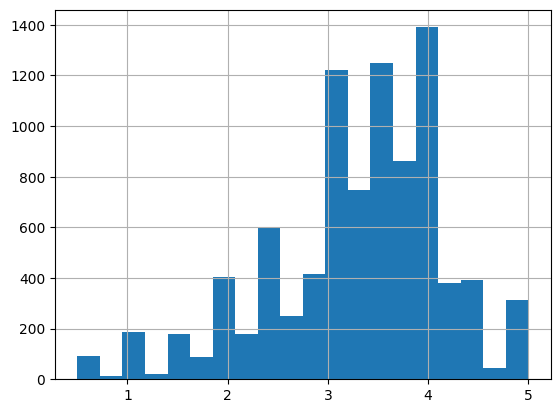

In [ ]:
# Example placeholder. Replace with your chosen target and feature set.
target = 'user_rating_mean'
features = ['genres', 'release_year', 'budget']

display(abt[[target] + features].isna().sum())
display(abt[target].describe())
display(abt[target].hist(bins=20))

abt.describe(include='all').T.head(25)


## Final Project Starter: Interpretation, Ethics, and Recommendations

Use this section to connect your analysis back to a business or research decision.

Address:

- Main finding
- What the model/analysis can and cannot support
- Limitations
- Ethics or responsible use concerns
- 2-3 cautious recommendations

### Read the Canvas final submission page first

Before completing this section, read the Canvas final submission assignment page. The Canvas page is the authoritative checklist for the final notebook, HTML report, required files, and submission format. Use this section to organize your final evidence and interpretation.



### Final report written workspace

Use this cell to draft the final interpretation required by the Canvas final submission page.

- Main finding:
- Evidence supporting the finding:
- Business or research implication:
- Limitations:
- Ethics/responsible use concerns:
- Recommendations:
- What you would improve with more time:



In [16]:
# Final project code workspace
# Save final datasets, figures, or tables here when they are ready.
# Recommended filenames:
# final_abt_path = OUTPUT_DIR / "movies_final_abt.csv"
# dictionary_path = OUTPUT_DIR / "movies_data_dictionary.csv"
# metrics_path = OUTPUT_DIR / "movies_model_metrics.csv"
# report_path = REPORTS_DIR / "movies_final_report.html"


In [17]:
# Save final deliverables only after your ABT and documentation are complete.
# abt.to_csv(OUTPUT_DIR / "movies_final_abt.csv", index=False)
# data_dictionary.to_csv(OUTPUT_DIR / "movies_data_dictionary.csv", index=False)

# Before final submission, restart the kernel, run all cells, and export the notebook to HTML.
